# Claude Usage Data Analysis

## Data Setup

In [2]:
%pip install pandas numpy matplotlib scikit-learn statsmodels
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict, GridSearchCV, validation_curve)
from sklearn.linear_model import (LinearRegression, LogisticRegression, LogisticRegressionCV,
                                  RidgeCV, LassoCV, ElasticNetCV)
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import LinearSVC, SVC, SVR
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             log_loss, mean_squared_error, r2_score, roc_auc_score, roc_curve,
                             RocCurveDisplay)
from statsmodels.stats.outliers_influence import variance_inflation_factor


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
claude_url = ("https://huggingface.co/datasets/Anthropic/EconomicIndex/resolve/main/"
       "release_2026_06_26/data/aei_claude_ai_2026-06-26.csv")

raw = pd.read_csv(claude_url)
print(raw.shape) 

(1636573, 10)


In [4]:
keep = raw[(raw["geo_level"] == "global") &
           (raw["hierarchy_level"] == 0) &
           (raw["date_start"] == "2026-05-01") &
           (raw["category_name"].isin(["onet", "soc_occupation"]))]

print("Rows kept:", len(keep), "of", len(raw))
keep.head()

Rows kept: 174864 of 1636573


,date_start,date_end,geo_id,geo_level,category_name,hierarchy_level,metric_id,value,node_name,node_external_id
1700,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.47,Recreational Vehicle Service Technicians,49-3092.00
1701,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.59,Gambling and Sports Book Writers and Runners,39-3012.00
1702,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.72,Occupational Therapists,29-1122.00
1703,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.82,"Multiple Machine Tool Setters, Operators, and ...",51-4081.00
1704,2026-05-01,2026-06-01,GLOBAL,global,soc_occupation,0,ai_autonomy_mean,2.65,"Library Science Teachers, Postsecondary",25-1082.00


In [5]:
def make_table(category):
    part = keep[keep["category_name"] == category]
    wide = part.pivot_table(index=["node_external_id", "node_name"],
                            columns="metric_id", values="value").reset_index()
    return wide

tasks = make_table("onet")                # one row per work task

print("Tasks:", tasks.shape)
tasks.head(3)

Tasks: (2713, 53)


metric_id,node_external_id,node_name,ai_autonomy_mean,ai_education_years_mean,artifact_academic_paper_or_thesis_pct,artifact_advice_or_recommendation_pct,artifact_analysis_or_summary_pct,artifact_app_or_website_pct,artifact_audio_or_music_pct,artifact_blog_or_article_pct,...,collaboration_validation_pct,human_education_years_mean,human_only_ability_pct,human_only_time_mean,human_with_ai_time_mean,multitasking_pct,pct,use_case_coursework_pct,use_case_personal_pct,use_case_work_pct
0,1,Resolve customer complaints regarding sales an...,2.37,10.25,0.0,12.3,2.46,0.00,0.0,0.0,...,0.83,9.65,97.54,2.39,49.05,53.28,0.0,1.64,29.51,68.85
1,10009,"List parts needed, estimate costs, and plan wo...",3.12,12.56,0.0,4.0,4.00,0.00,0.0,0.0,...,4.17,12.16,84.00,6.98,33.04,8.00,0.0,4.00,24.00,72.00
2,10027,Explain assembly procedures or techniques to o...,2.59,12.35,0.0,0.0,0.00,11.76,0.0,0.0,...,0.00,11.35,64.71,5.69,67.44,17.65,0.0,52.94,35.29,11.76


In [6]:
def add_target(df):
    df = df.dropna(subset=["human_only_time_mean", "human_with_ai_time_mean"]).copy()
    df = df[df["human_with_ai_time_mean"] > 0]
    df["time_savings"] = (df["human_only_time_mean"] * 60) / df["human_with_ai_time_mean"]
    df["log_time_savings"] = np.log(df["time_savings"])
    return df

tasks = add_target(tasks)

tasks["log_time_savings"] = np.log(tasks["time_savings"])
tasks = add_target(tasks)

In [7]:
# Dropping irrelevant columns for predicting time_savings from dataset (i.e., id fields)

tasks_cut = tasks.drop(columns=["time_savings", "node_external_id", "node_name", "human_only_time_mean", "human_with_ai_time_mean", "pct",
"collaboration_bucket_augmentation_pct", "collaboration_bucket_automation_pct", "collaboration_none_pct", "use_case_personal_pct", "artifact_none_pct"])

print(tasks_cut.shape) 

(2703, 44)


In [8]:
# Remove rows with any blank values just for simplicity. There's only 6.

tasks_cut = tasks_cut.dropna().copy()
print(tasks_cut.shape)

(2697, 44)


## Weeks 1-6 Material

In [9]:
# Creating our X and y

y = tasks_cut["log_time_savings"]  
X = tasks_cut.drop(columns=["log_time_savings"])

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [11]:
# Adding the best interaction and squared terms from Milestone 1
X_train["autonomy_edu"] = X_train["ai_autonomy_mean"] * X_train["ai_education_years_mean"]
X_train["autonomy_sq"] = X_train["ai_autonomy_mean"] ** 2

X_test["autonomy_edu"] = X_test["ai_autonomy_mean"] * X_test["ai_education_years_mean"]
X_test["autonomy_sq"] = X_test["ai_autonomy_mean"] ** 2

# OLS model with the added terms (predicting log time savings)
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test, has_constant="add")
model = sm.OLS(y_train, X_train_sm).fit()
pred = model.predict(X_test_sm)

print(f"OLS + added terms | Train R2: {model.rsquared:.3f}   Adj R2: {model.rsquared_adj:.3f}")
print(f"OLS + added terms | Test R2: {r2_score(y_test, pred):.3f}   "
      f"Test RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f} (log units)")

# Ranking statistically significant coefficients (t value)
coef = pd.DataFrame({"coef": model.params, "p_value": model.pvalues,
                     "abs_t": model.tvalues.abs()}).drop("const")
print(coef.sort_values("abs_t", ascending=False).head(10).round(3))


# Scaling the features (needed for the models below)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# One function to print the same scores for every model
def score(model, name, X_tr, X_te, n_features):
    train_r2 = r2_score(y_train, model.predict(X_tr))
    n = len(y_train)
    adj_r2 = 1 - (1 - train_r2) * (n - 1) / (n - n_features - 1)
    pred = model.predict(X_te)
    print(name, "| Train R2:", round(train_r2, 3), "| Adj R2:", round(adj_r2, 3),
          "| Test R2:", round(r2_score(y_test, pred), 3),
          "| Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))


# Ridge, Lasso, Elastic Net
alphas = np.logspace(-5, 2, 50)   # penalty strengths from 0.00001 to 100

ridge = RidgeCV(alphas=alphas, cv=5).fit(X_train_s, y_train)
lasso = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000).fit(X_train_s, y_train)
enet = ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], alphas=alphas, cv=5,
                    random_state=42, max_iter=10000).fit(X_train_s, y_train)

print("Best alpha - Ridge:", ridge.alpha_)
print("Best alpha - Lasso:", lasso.alpha_)
print("Best alpha - Elastic Net:", enet.alpha_, "| l1_ratio:", enet.l1_ratio_)

p = X_train_s.shape[1]   # number of features (45)
score(ridge, "Ridge", X_train_s, X_test_s, p)
score(lasso, "Lasso", X_train_s, X_test_s, p)
score(enet, "Elastic Net", X_train_s, X_test_s, p)


# Forward selection (10 features)
selector = SequentialFeatureSelector(LinearRegression(), n_features_to_select=10,
                                     direction="forward", cv=5)
selector.fit(X_train_s, y_train)
fwd_keep = selector.get_support()
print("Forward selection picked:", list(X_train.columns[fwd_keep]))

fwd_model = LinearRegression().fit(X_train_s[:, fwd_keep], y_train)
score(fwd_model, "Forward (10)", X_train_s[:, fwd_keep], X_test_s[:, fwd_keep], 10)


# PCR and PLSR for different numbers of components
for n in [5, 10, 20, 30]:
    pca_n = PCA(n_components=n)
    X_train_pca = pca_n.fit_transform(X_train_s)
    X_test_pca = pca_n.transform(X_test_s)
    pcr_model = LinearRegression().fit(X_train_pca, y_train)
    score(pcr_model, f"PCR ({n})", X_train_pca, X_test_pca, n)

    pls = PLSRegression(n_components=n).fit(X_train_s, y_train)
    score(pls, f"PLSR ({n})", X_train_s, X_test_s, n)


# Tuned RBF SVR
rbf_grid = GridSearchCV(SVR(kernel="rbf"),
                        param_grid={"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, "scale"]},
                        scoring="r2", cv=5)
rbf_grid.fit(X_train_s, y_train)
print("Best RBF settings:", rbf_grid.best_params_)
score(rbf_grid, "Tuned RBF SVR", X_train_s, X_test_s, p)


OLS + added terms | Train R2: 0.734   Adj R2: 0.729
OLS + added terms | Test R2: 0.765   Test RMSE: 0.293 (log units)
                                        coef  p_value  abs_t
autonomy_edu                           0.127      0.0  9.025
artifact_advice_or_recommendation_pct -0.009      0.0  7.690
artifact_config_or_infra_pct          -0.012      0.0  7.212
ai_autonomy_mean                      -2.890      0.0  7.095
use_case_work_pct                      0.003      0.0  5.853
collaboration_feedback_loop_pct       -0.010      0.0  5.828
artifact_explanation_or_answer_pct    -0.007      0.0  5.795
artifact_email_or_message_pct         -0.007      0.0  5.769
ai_education_years_mean               -0.208      0.0  5.462
multitasking_pct                      -0.005      0.0  5.389
Best alpha - Ridge: 0.2682695795279722
Best alpha - Lasso: 5.1794746792312125e-05
Best alpha - Elastic Net: 7.196856730011514e-05 | l1_ratio: 0.5
Ridge | Train R2: 0.734 | Adj R2: 0.728 | Test R2: 0.765 | Test R

## Week 10: Clustering P1

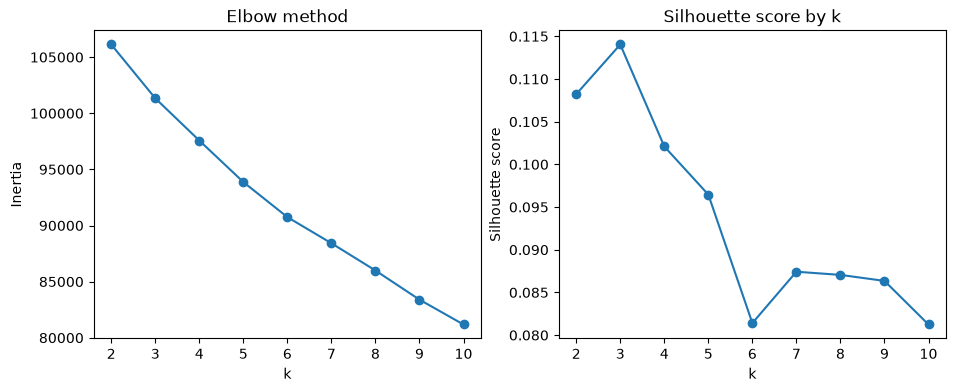

In [12]:
# K-Means
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Scale the features (K-Means uses distance, like KNN)
Xs = StandardScaler().fit_transform(X)

k_values = range(2, 11)
inertia = []
silhouette = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(Xs)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(Xs, labels))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_values, inertia, marker="o")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertia")
ax[0].set_title("Elbow method")

ax[1].plot(k_values, silhouette, marker="o")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette score by k")
plt.show()

In [13]:
best_k = 3

km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_labels = km.fit_predict(Xs) + 1   # clusters = 1, 2, 3 instead of 0, 1, 2

print("Silhouette:", round(silhouette_score(Xs, km_labels), 3))
print(pd.Series(km_labels).value_counts().sort_index())

Silhouette: 0.114
1     349
2     833
3    1515
Name: count, dtype: int64


In [14]:
# Adding time savings

summary = pd.DataFrame({"cluster": km_labels, "log_ts": y.values}).groupby("cluster")["log_ts"].agg(["count", "mean"])
summary["times faster"] = np.exp(summary["mean"]).round(2)
print(summary.round(3))

         count   mean  times faster
cluster                            
1          349  2.171          8.77
2          833  1.463          4.32
3         1515  2.195          8.98


                                       1     2     3
metric_id                                           
artifact_script_or_snippet_pct      1.41 -0.32 -0.15
artifact_app_or_website_pct         1.37 -0.27 -0.17
human_only_ability_pct             -1.25  0.51  0.01
use_case_work_pct                   0.26 -1.05  0.52
artifact_explanation_or_answer_pct -0.44  0.99 -0.44


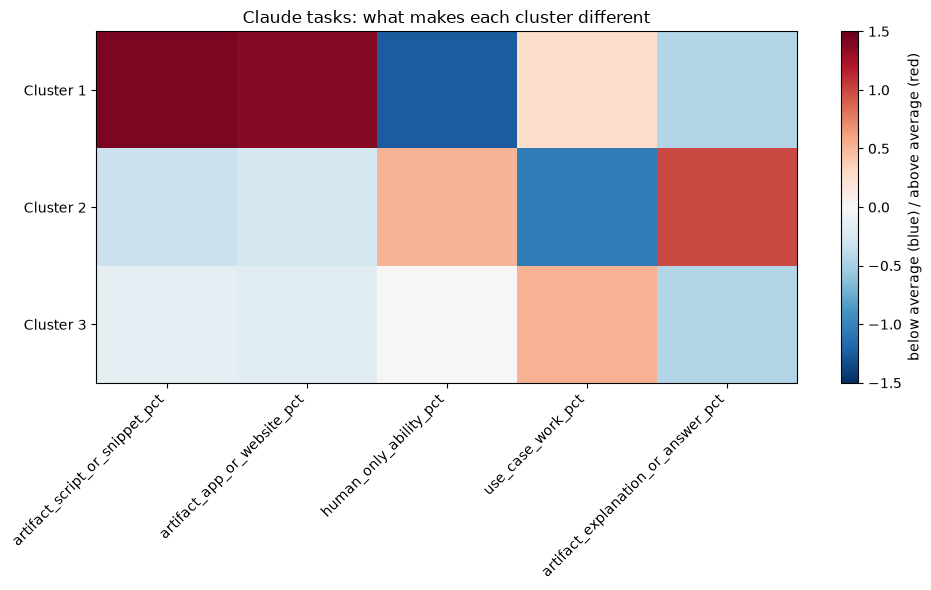

In [15]:
# Scaled averages: 0 = average task, positive = above average, negative = below average
profile = pd.DataFrame(Xs, columns=X.columns).groupby(km_labels).mean()

# Keeping the 5 features that differ the most between clusters
top = profile.std().sort_values(ascending=False).head(5).index
print(profile[top].round(2).T)

plt.figure(figsize=(10, 6))
plt.imshow(profile[top], cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
plt.colorbar(label="below average (blue) / above average (red)")
plt.xticks(range(len(top)), top, rotation=45, ha="right")
plt.yticks(range(best_k), [f"Cluster {c}" for c in profile.index])   # shows Cluster 1, 2, 3
plt.title("Claude tasks: what makes each cluster different")
plt.tight_layout()
plt.show()

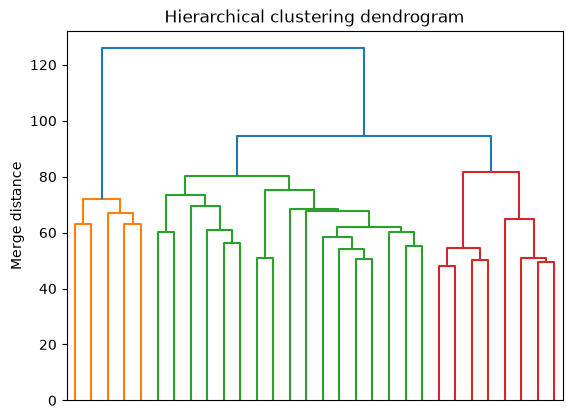

In [16]:
from scipy.cluster.hierarchy import linkage, dendrogram

links = linkage(Xs, method="ward")

dendrogram(links, truncate_mode="lastp", p=30, no_labels=True)
plt.ylabel("Merge distance")
plt.title("Hierarchical clustering dendrogram")
plt.show()

In [17]:
from sklearn.cluster import AgglomerativeClustering

hier_labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xs) + 1
print("Silhouette:", round(silhouette_score(Xs, hier_labels), 3))

summary = pd.DataFrame({"cluster": hier_labels, "log_ts": y.values}).groupby("cluster")["log_ts"].agg(["count", "mean"])
summary["times faster"] = np.exp(summary["mean"]).round(2)
print(summary.round(3))

Silhouette: 0.088
         count   mean  times faster
cluster                            
1          344  2.074          7.96
2          688  1.479          4.39
3         1665  2.145          8.54


In [19]:
from sklearn.cluster import DBSCAN

db_labels = DBSCAN(eps=4, min_samples=10).fit_predict(Xs)

# -1 = noise, so leave those tasks out of the score
keep_rows = db_labels != -1
print("Silhouette:", round(silhouette_score(Xs[keep_rows], db_labels[keep_rows]), 3))
print(pd.Series(db_labels).value_counts().sort_index())

Silhouette: 0.326
-1     398
 0    2273
 1      16
 2      10
Name: count, dtype: int64
